# Exploratory Data Analysis (EDA)

## 1. Introduction

Exploratory Data Analysis (EDA) is the process of examining, summarizing, and visualizing a dataset to understand its structure, identify patterns, detect unusual observations, and discover relationships between variables.

## 2. Project Objective

The objective of this analysis is to explore household electricity consumption data and identify meaningful patterns that can support better energy monitoring and consumption analysis.

## 3. Dataset Overview

The dataset contains minute-level household electricity measurements, including active power, reactive power, voltage, current intensity, and three sub-metering measurements.

## 4. EDA Activities

* Analyze the statistical distribution of numerical variables.
* Examine electricity consumption patterns and trends.
* Explore relationships between electrical measurements.
* Identify unusual observations and potential anomalies.
* Summarize findings that can be used in the dashboard.

## 5. Tools and Libraries

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn

## 6. Expected Outcome

The analysis will help identify important consumption patterns, understand relationships between electrical variables, and generate evidence-based insights for the Electricity Consumption Intelligence Dashboard.


In [2]:
import pandas as pd

df = pd.read_csv(
    "cleaned_electricity_data.csv",
    parse_dates=['Date', 'Datetime']
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (2049280, 17)


In [3]:
print("Dataset Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Columns:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Datetime', 'Hour', 'Day_of_Week', 'Day', 'Month', 'Year', 'Is_Weekend', 'Energy_kWh']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2049280 entries, 0 to 2049279
Data columns (total 17 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Date                   datetime64[us]
 1   Time                   str           
 2   Global_active_power    float64       
 3   Global_reactive_power  float64       
 4   Voltage                float64       
 5   Global_intensity       float64       
 6   Sub_metering_1         float64       
 7   Sub_metering_2         float64       
 8   Sub_metering_3         float64       
 9   Datetime               datetime64[us]
 10  Hour                   int64         
 11  Day_of_Week            str           
 12  Day            

## 1. Statistical Summary of the Dataset

In this section, we examine the statistical properties of the numerical variables using descriptive statistics.

The analysis includes:

* Mean: Average value.
* Standard deviation: How much the values vary.
* Minimum and maximum: The smallest and largest values.
* Quartiles: The distribution of values across the dataset.

**Objective:** Understand typical electricity consumption levels and identify variables that may require further investigation.


In [4]:
df.describe().round(3)

,Date,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime,Hour,Day,Month,Year,Energy_kWh
count,2049280,2049280.000,2049280.000,2049280.00,2049280.000,2049280.000,2049280.000,2049280.000,2049280,2049280.000,2049280.000,2049280.000,2049280.000,2049280.000
mean,2008-12-01 13:00:00.309182,1.092,0.124,240.84,4.628,1.122,1.299,6.458,2008-12-02 00:59:44.397739,11.504,15.712,6.454,2008.425,0.018
min,2006-12-16 00:00:00,0.076,0.000,223.20,0.200,0.000,0.000,0.000,2006-12-16 17:24:00,0.000,1.000,1.000,2006.000,0.001
25%,2007-12-10 00:00:00,0.308,0.048,238.99,1.400,0.000,0.000,0.000,2007-12-10 05:37:45,5.000,8.000,3.000,2007.000,0.005
50%,2008-11-30 00:00:00,0.602,0.100,241.01,2.600,0.000,0.000,1.000,2008-11-30 01:22:30,12.000,16.000,6.000,2008.000,0.010
75%,2009-11-23 00:00:00,1.528,0.194,242.89,6.400,0.000,1.000,17.000,2009-11-23 20:31:15,18.000,23.000,9.000,2009.000,0.025
max,2010-11-26 00:00:00,11.122,1.390,254.15,48.400,88.000,80.000,31.000,2010-11-26 21:02:00,23.000,31.000,12.000,2010.000,0.185
std,NaN,1.057,0.113,3.24,4.444,6.153,5.822,8.437,NaN,6.925,8.802,3.423,1.124,0.018


## 2. Missing Values Analysis

Missing values can affect statistical calculations, visualizations, and analytical conclusions.

In this section, we will calculate the number and percentage of missing values in each column to assess the completeness of the cleaned dataset.

**Objective:** Verify data completeness before proceeding with further exploratory analysis.


In [5]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate missing-value percentage
missing_percentage = (missing_values / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage (%)': missing_percentage.round(3)
})

# Display the results
print("Missing Values Analysis:")
display(missing_summary)

Missing Values Analysis:


,Missing Values,Missing Percentage (%)
Date,0,0.0
Time,0,0.0
Global_active_power,0,0.0
Global_reactive_power,0,0.0
Voltage,0,0.0
Global_intensity,0,0.0
Sub_metering_1,0,0.0
Sub_metering_2,0,0.0
Sub_metering_3,0,0.0
Datetime,0,0.0


## 3. Distribution of Electricity Consumption

Distribution analysis helps us understand how electricity consumption values are spread across the dataset.

We will examine Global Active Power to identify common consumption ranges, understand variation, and investigate whether the distribution is symmetrical or skewed.

**Objective:** Understand typical household power consumption and identify values that may require further investigation.


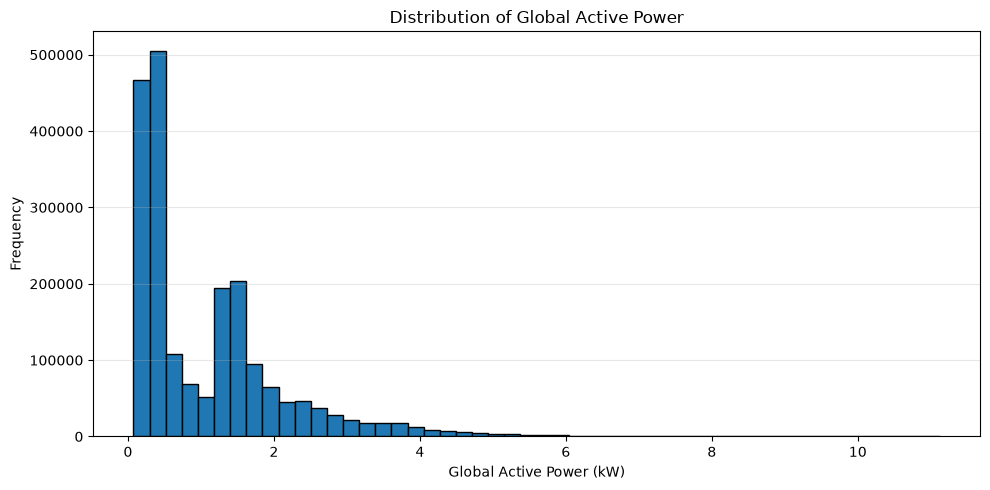

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df['Global_active_power'],
    bins=50,
    edgecolor='black'
)

plt.title('Distribution of Global Active Power')
plt.xlabel('Global Active Power (kW)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Key Finding

The histogram shows that Global Active Power readings are concentrated at lower values, with fewer observations at higher power levels. This suggests that the distribution is likely right-skewed.

**Practical significance:** Understanding this distribution can help distinguish typical household power usage from periods of unusually high demand. Further analysis is needed before classifying any observation as an anomaly.


In [7]:
skewness = df['Global_active_power'].skew()

print("Global Active Power Skewness:", round(skewness, 3))

Global Active Power Skewness: 1.786


### Key Finding: Right-Skewed Electricity Consumption

The skewness of Global Active Power is **1.786**, indicating a positively skewed distribution. The mean active power (1.092 kW) is greater than the median (0.602 kW), supporting this observation.

**Practical significance:** Most recorded power readings occur at relatively lower levels, while a smaller number of high-power readings extend the distribution to the right. This finding can help guide further investigation into periods of high electricity demand.


## 4. Hourly Electricity Consumption Analysis

Electricity consumption can vary throughout the day depending on household activities and electrical loads.

In this section, we will calculate the average active power for each hour, from 0 to 23, to identify periods of relatively high and low demand.

**Objective:** Understand hourly consumption patterns and identify the hours with the highest and lowest average active power.


In [8]:
hourly_analysis = df.groupby('Hour').agg(
    Average_Power_kW=('Global_active_power', 'mean')
).reset_index()

print(hourly_analysis.round(3))

    Hour  Average_Power_kW
0      0             0.659
1      1             0.539
2      2             0.481
3      3             0.445
4      4             0.444
5      5             0.454
6      6             0.792
7      7             1.502
8      8             1.461
9      9             1.332
10    10             1.261
11    11             1.246
12    12             1.207
13    13             1.145
14    14             1.083
15    15             0.991
16    16             0.949
17    17             1.055
18    18             1.326
19    19             1.733
20    20             1.899
21    21             1.878
22    22             1.413
23    23             0.902


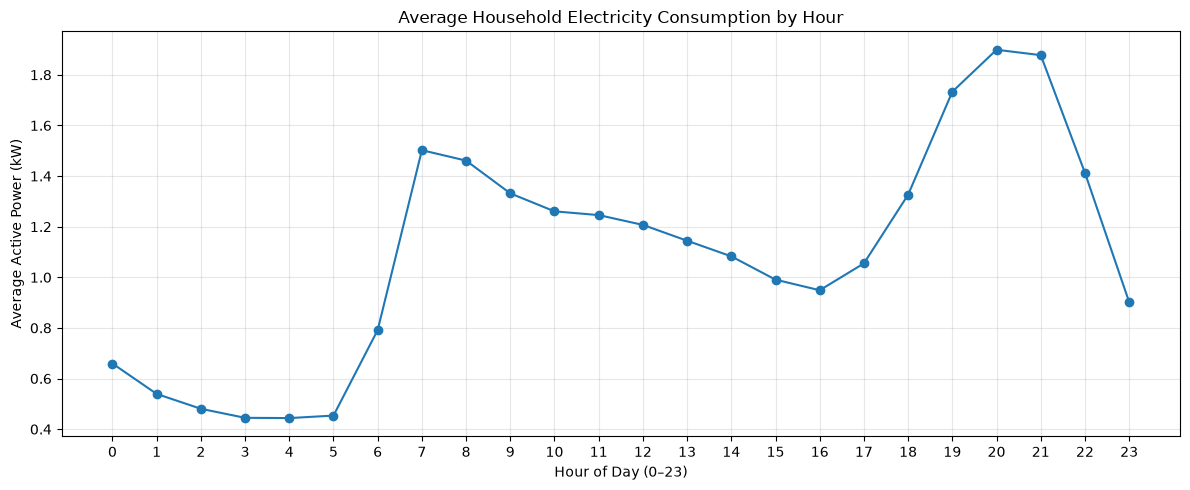

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_analysis['Hour'],
    hourly_analysis['Average_Power_kW'],
    marker='o'
)

plt.title('Average Household Electricity Consumption by Hour')
plt.xlabel('Hour of Day (0–23)')
plt.ylabel('Average Active Power (kW)')

plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Key Findings: Hourly Electricity Consumption

The hourly analysis shows noticeable variations in household active power throughout the day.

* **Peak hour:** 8 PM, with an average active power of 1.899 kW.
* **Lowest-demand hour:** 4 AM, with an average active power of 0.444 kW.
* **Morning pattern:** Average power increases during the early morning hours.
* **Evening pattern:** Power rises again during the evening, reaching its maximum at 8 PM.

**Practical significance:** Understanding hourly demand patterns can help users identify periods of higher electricity usage and make more informed energy-management decisions.


## 5. Daily Electricity Consumption Analysis

Daily analysis helps us understand how household electricity usage changes over time.

In this section, we will calculate the total recorded energy consumption for each day and identify days with relatively high or low consumption.

**Objectives:**

* Examine daily energy consumption patterns.
* Identify the days with the highest and lowest recorded consumption.
* Investigate daily variations in household electricity usage.

**Note:** Daily totals are based on the available valid readings. Missing measurement intervals were removed during data cleaning, so totals may underestimate actual consumption.


In [10]:
daily_analysis = df.groupby(df['Date'].dt.date).agg(
    Total_Energy_kWh=('Energy_kWh', 'sum'),
    Average_Power_kW=('Global_active_power', 'mean')
).reset_index()

daily_analysis.rename(columns={'Date': 'Date'}, inplace=True)

print("Daily Analysis:")
print(daily_analysis.head())

print("\nTotal days analyzed:", len(daily_analysis))

Daily Analysis:
         Date  Total_Energy_kWh  Average_Power_kW
0  2006-12-16         20.152933          3.053475
1  2006-12-17         56.507667          2.354486
2  2006-12-18         36.730433          1.530435
3  2006-12-19         27.769900          1.157079
4  2006-12-20         37.095800          1.545658

Total days analyzed: 1433


In [11]:
# Day with the highest recorded energy consumption
highest_day = daily_analysis.loc[
    daily_analysis['Total_Energy_kWh'].idxmax()
]

# Day with the lowest recorded energy consumption
lowest_day = daily_analysis.loc[
    daily_analysis['Total_Energy_kWh'].idxmin()
]

print("Highest Consumption Day:")
print(highest_day)

print("\nLowest Consumption Day:")
print(lowest_day)

Highest Consumption Day:
Date                2006-12-23
Total_Energy_kWh     79.556433
Average_Power_kW      3.314851
Name: 7, dtype: object

Lowest Consumption Day:
Date                2009-06-13
Total_Energy_kWh      0.236967
Average_Power_kW      0.473933
Name: 909, dtype: object


### Key Findings: Daily Electricity Consumption

The daily analysis examined electricity consumption across 1,433 distinct dates.

* **Highest recorded consumption:** 23 December 2006, with 79.556 kWh.
* **Lowest recorded consumption:** 13 June 2009, with 0.237 kWh.
* **Daily variation:** Recorded energy consumption varies considerably across different dates.

**Practical significance:** Daily consumption analysis can help households, colleges, and industries identify periods of high electricity demand and investigate unusual consumption patterns.

**Data limitation:** Missing measurement intervals were removed during data cleaning. Therefore, daily totals may underestimate actual consumption, particularly on days with incomplete readings. The lowest recorded total should not automatically be interpreted as genuinely low usage.


In [12]:
daily_readings = df.groupby(df['Date'].dt.date).size()

print("Readings on highest-consumption day:",
      daily_readings.loc[highest_day['Date']])

print("Readings on lowest-consumption day:",
      daily_readings.loc[lowest_day['Date']])

Readings on highest-consumption day: 1440
Readings on lowest-consumption day: 30


### Data Quality Finding: Incomplete Daily Readings

A comparison of the highest- and lowest-consumption days revealed an important difference in data completeness.

* **23 December 2006:** 1,440 readings were available, representing a complete day of minute-level measurements.
* **13 June 2009:** Only 30 readings were available, representing approximately 2.08% of the expected daily readings.

**Key Insight:** The lowest recorded daily energy total cannot be treated as the household's actual lowest-consumption day because most of that day's readings are unavailable.

**Project improvement:** The dashboard can flag days with insufficient readings and display data-completeness information alongside daily consumption results. This helps prevent misleading conclusions.


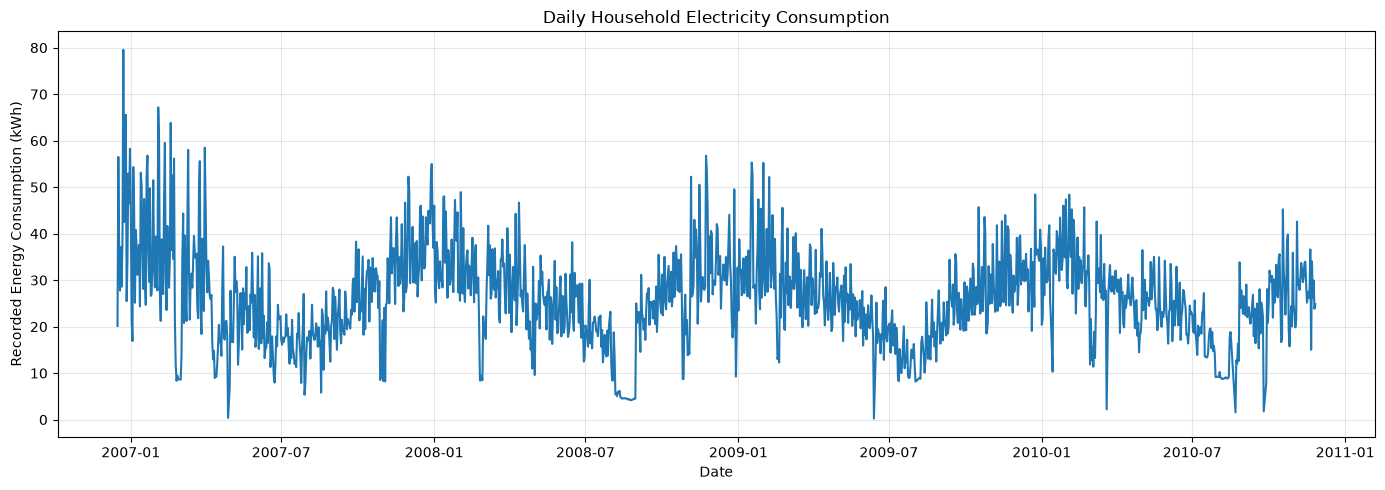

In [13]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_analysis['Date'],
    daily_analysis['Total_Energy_kWh']
)

plt.title('Daily Household Electricity Consumption')
plt.xlabel('Date')
plt.ylabel('Recorded Energy Consumption (kWh)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Key Findings: Daily Electricity Consumption Trend

The daily consumption chart visualizes changes in recorded household energy consumption over time.

* **Consumption variability:** Daily energy consumption changes across the observation period.
* **High-consumption periods:** Peaks indicate days with higher recorded energy usage and may warrant further investigation.
* **Data-quality consideration:** Sudden drops may reflect incomplete measurements rather than a genuine reduction in electricity consumption.

**Practical significance:** Similar analysis can help households monitor energy usage, colleges identify periods of high demand, and industries investigate unusual consumption patterns.

**Limitation:** Daily totals should be interpreted alongside the number of valid readings. Days with incomplete measurements may not be directly comparable with complete days.


## 6. Weekday vs Weekend Electricity Consumption

This analysis compares household electricity consumption on weekdays and weekends.

### Objectives

* Compare average active power on weekdays and weekends.
* Identify differences in electricity usage patterns.
* Explore how daily routines may relate to household electricity demand.

**Method:** Each reading is classified as either a weekday or a weekend reading using the date.

**Limitation:** The analysis compares recorded measurements and does not establish the reasons behind any observed differences.


In [14]:
# Compare weekday and weekend electricity consumption

df['Day_Type'] = df['Is_Weekend'].map({
    False: 'Weekday',
    True: 'Weekend'
})

day_type_analysis = df.groupby('Day_Type').agg(
    Average_Power_kW=('Global_active_power', 'mean'),
    Total_Energy_kWh=('Energy_kWh', 'sum'),
    Number_of_Readings=('Global_active_power', 'count')
).reset_index()

print("Weekday vs Weekend Analysis:")
print(day_type_analysis.round(3))

Weekday vs Weekend Analysis:
  Day_Type  Average_Power_kW  Total_Energy_kWh  Number_of_Readings
0  Weekday             1.035         25376.452             1470428
1  Weekend             1.234         11907.296              578852


### Key Findings: Weekday vs Weekend Consumption

The analysis shows differences in household electricity consumption between weekdays and weekends.

* **Weekday average active power:** 1.035 kW.
* **Weekend average active power:** 1.234 kW.
* **Difference:** Average active power is approximately 19.2% higher on weekends.
* **Total energy:** Weekday energy is higher in the dataset because more weekday readings are available.

**Practical significance:** Understanding these patterns can help households and facility managers investigate when electricity demand tends to be higher and plan energy-saving measures.

**Limitation:** The observed difference does not establish its cause. Total energy comparisons must also account for the number of recorded readings.


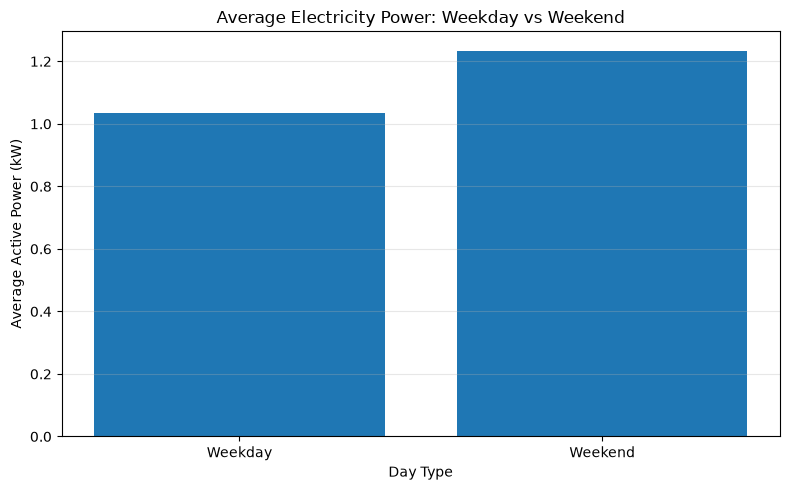

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(
    day_type_analysis['Day_Type'],
    day_type_analysis['Average_Power_kW']
)

plt.title('Average Electricity Power: Weekday vs Weekend')
plt.xlabel('Day Type')
plt.ylabel('Average Active Power (kW)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Monthly Electricity Consumption Analysis

Monthly analysis helps identify long-term patterns and variations in household electricity consumption.

### Objectives

* Calculate total recorded energy consumption for each month.
* Compare electricity consumption across months and years.
* Identify months with relatively high or low recorded consumption.

**Method:** The dataset will be grouped by year and month to calculate monthly energy totals and average active power.

**Limitation:** Monthly totals can be affected by missing measurement intervals. Comparisons should also account for differences in the number of days in each month.


In [16]:
# Analyze monthly electricity consumption

monthly_analysis = df.groupby(['Year', 'Month']).agg(
    Total_Energy_kWh=('Energy_kWh', 'sum'),
    Average_Power_kW=('Global_active_power', 'mean')
).reset_index()

print("Monthly Electricity Consumption:")
print(monthly_analysis.head(12).round(3))

print("\nTotal months analyzed:", len(monthly_analysis))

Monthly Electricity Consumption:
    Year  Month  Total_Energy_kWh  Average_Power_kW
0   2006     12           696.888             1.901
1   2007      1          1150.198             1.546
2   2007      2           941.481             1.401
3   2007      3           981.037             1.319
4   2007      4           586.358             0.891
5   2007      5           733.481             0.986
6   2007      6           594.714             0.827
7   2007      7           495.064             0.667
8   2007      8           568.274             0.764
9   2007      9           697.877             0.969
10  2007     10           821.273             1.104
11  2007     11           931.977             1.294

Total months analyzed: 48


### Initial Findings: Monthly Electricity Consumption

The monthly analysis groups household electricity readings by year and month to examine long-term consumption patterns.

* January 2007 recorded 1,150.198 kWh of energy.
* July 2007 recorded 495.064 kWh of energy.
* Average active power varied across the months shown.

**Practical significance:** Monthly analysis can help households and facility managers monitor consumption trends, compare periods, and investigate months with unusually high or low recorded usage.

**Limitation:** These observations cover only the months displayed. Missing readings and differences in month length can affect monthly totals. Further analysis is required to identify the overall highest and lowest months.


In [17]:
# Identify the highest- and lowest-consumption months

highest_month = monthly_analysis.loc[
    monthly_analysis['Total_Energy_kWh'].idxmax()
]

lowest_month = monthly_analysis.loc[
    monthly_analysis['Total_Energy_kWh'].idxmin()
]

print("Highest Consumption Month:")
print(highest_month)

print("\nLowest Consumption Month:")
print(lowest_month)

Highest Consumption Month:
Year                2007.000000
Month                 12.000000
Total_Energy_kWh    1210.069500
Average_Power_kW       1.626474
Name: 12, dtype: float64

Lowest Consumption Month:
Year                2008.000000
Month                  8.000000
Total_Energy_kWh     205.698000
Average_Power_kW       0.276488
Name: 20, dtype: float64


### Key Findings: Monthly Electricity Consumption

The analysis examined 48 months of household electricity data.

* **Highest recorded monthly consumption:** December 2007, with 1,210.070 kWh.
* **Lowest recorded monthly consumption:** August 2008, with 205.698 kWh.
* **Overall observation:** Recorded monthly energy consumption varies considerably throughout the observation period.

**Practical significance:** Monthly monitoring can help households, colleges, and industries identify periods with high recorded energy usage and investigate potential opportunities for energy savings.

**Data limitation:** Monthly totals can be affected by missing measurement intervals and incomplete days. These results describe recorded consumption and do not, by themselves, establish the reasons for the observed differences.


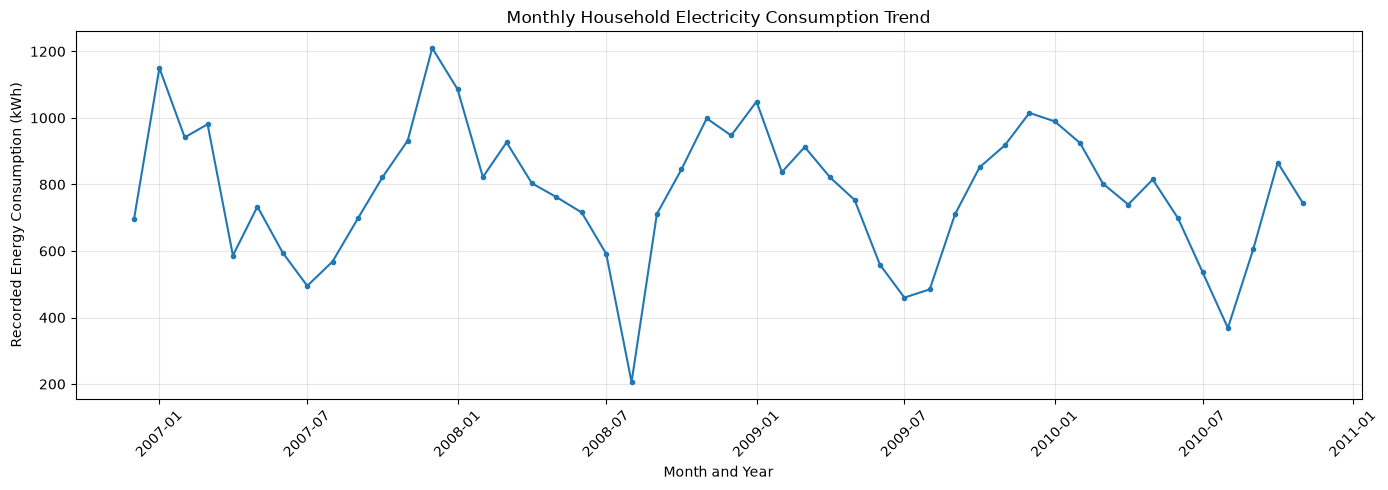

In [18]:
# Create a proper monthly date for the x-axis

monthly_analysis['Month_Date'] = pd.to_datetime(
    monthly_analysis[['Year', 'Month']].assign(DAY=1)
)

# Plot monthly electricity consumption

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_analysis['Month_Date'],
    monthly_analysis['Total_Energy_kWh'],
    marker='o',
    markersize=3
)

plt.title('Monthly Household Electricity Consumption Trend')
plt.xlabel('Month and Year')
plt.ylabel('Recorded Energy Consumption (kWh)')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Correlation Analysis

Correlation analysis helps us understand how electrical measurements are related to one another.

### Objectives

* Examine relationships between active power, reactive power, voltage, and current intensity.
* Investigate relationships between the electrical measurements and sub-metering variables.
* Identify potentially useful relationships for the Electricity Consumption Intelligence Dashboard.

### Method

We will calculate the correlation coefficients between numerical electrical measurements and visualize them using a correlation heatmap.

**Interpretation:** Correlation coefficients range from -1 to +1. Positive values indicate that two variables tend to increase together, while negative values indicate that one tends to decrease as the other increases. Correlation does not establish causation.


In [19]:
# Select electrical measurement columns for correlation analysis

electrical_columns = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

correlation_matrix = df[electrical_columns].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

Correlation Matrix:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Global_active_power,1.00,0.25,-0.40,1.00,0.48,0.43,0.64
Global_reactive_power,0.25,1.00,-0.11,0.27,0.12,0.14,0.09
Voltage,-0.40,-0.11,1.00,-0.41,-0.20,-0.17,-0.27
Global_intensity,1.00,0.27,-0.41,1.00,0.49,0.44,0.63
Sub_metering_1,0.48,0.12,-0.20,0.49,1.00,0.05,0.10
Sub_metering_2,0.43,0.14,-0.17,0.44,0.05,1.00,0.08
Sub_metering_3,0.64,0.09,-0.27,0.63,0.10,0.08,1.00


### Key Findings: Correlation Analysis

The correlation matrix reveals several relationships between household electrical measurements.

* **Active power and global intensity:** Correlation of approximately +1.00, indicating an almost perfectly positive linear relationship.
* **Active power and Sub-metering 3:** Correlation of +0.64, indicating a moderately strong positive relationship.
* **Active power and voltage:** Correlation of −0.40, indicating a moderate negative relationship.
* **Active power and reactive power:** Correlation of +0.25, indicating a relatively weak positive linear relationship.

**Practical significance:** Correlation analysis helps identify relationships between electrical measurements and can guide further investigation into household electricity consumption patterns.

**Limitation:** Correlation does not establish causation. The relationships describe the observed dataset and should not be assumed to hold identically in every household.


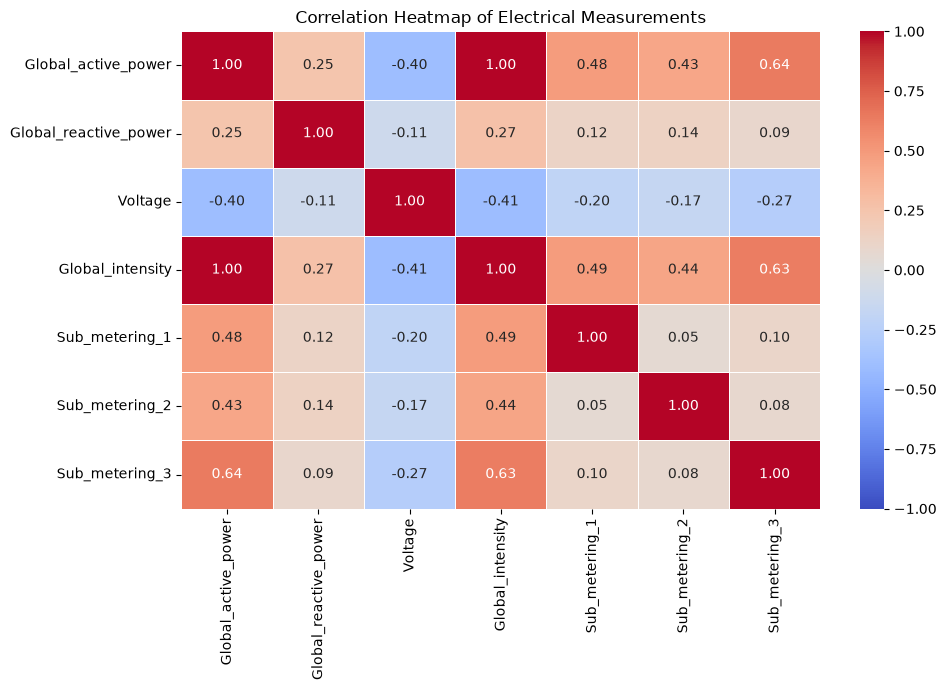

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title('Correlation Heatmap of Electrical Measurements')
plt.tight_layout()
plt.show()

## 9. Outlier and Anomaly Analysis

Outlier analysis helps identify observations that are unusually high or low compared with the general distribution of electricity measurements.

In this section, we will examine the distribution of Global Active Power and identify unusually high power readings using the Interquartile Range (IQR) method.

### Objectives

* Understand the spread of household electricity power readings.
* Identify observations that are statistically unusual.
* Investigate whether high-power readings may require further analysis.
* Generate useful information for the Electricity Consumption Intelligence Dashboard.

### Method: Interquartile Range (IQR)

The IQR method uses the first quartile (Q1) and third quartile (Q3) to calculate the typical spread of the data.

* **IQR = Q3 − Q1**
* **Lower limit = Q1 − 1.5 × IQR**
* **Upper limit = Q3 + 1.5 × IQR**

Readings outside these limits are classified as potential statistical outliers.

**Important note:** An outlier is not necessarily an error or an electrical fault. A high reading may reflect genuine household electricity usage. We will identify unusual readings without automatically removing them.


In [21]:
Q1 = df['Global_active_power'].quantile(0.25)
Q3 = df['Global_active_power'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("First Quartile (Q1):", round(Q1, 3))
print("Third Quartile (Q3):", round(Q3, 3))
print("Interquartile Range (IQR):", round(IQR, 3))
print("Lower Limit:", round(lower_limit, 3))
print("Upper Limit:", round(upper_limit, 3))

First Quartile (Q1): 0.308
Third Quartile (Q3): 1.528
Interquartile Range (IQR): 1.22
Lower Limit: -1.522
Upper Limit: 3.358


In [22]:
outliers = df[df['Global_active_power'] > upper_limit]

outlier_count = len(outliers)
total_readings = len(df)

outlier_percentage = (outlier_count / total_readings) * 100

print("Potential High-Power Outliers:", outlier_count)
print("Total Readings:", total_readings)
print("Percentage of Outliers:", round(outlier_percentage, 2), "%")

Potential High-Power Outliers: 94907
Total Readings: 2049280
Percentage of Outliers: 4.63 %


### Key Findings: Outlier Analysis

The Interquartile Range (IQR) method was used to identify potential high-power outliers in the household electricity consumption dataset.

The upper outlier limit was calculated as **3.358 kW**.

* **Total valid readings:** 2,049,280
* **Potential high-power outliers:** 94,907
* **Percentage of potential outliers:** 4.63%

**Interpretation:** Approximately 4.63% of the recorded active-power readings exceed the calculated upper limit. These observations are statistically unusual compared with the central distribution of the data.

**Practical significance:** In the Electricity Consumption Intelligence Dashboard, these readings can be highlighted for further investigation. For example, a household might examine whether high-demand periods coincide with the simultaneous use of multiple electrical appliances.

**Limitation:** Statistical outliers do not automatically indicate electricity wastage, equipment failure, or an electrical fault. The readings should be investigated in context, and valid observations should not be removed without a clear reason.


C:\Users\vijay\AppData\Local\Temp\ipykernel_15812\3409647784.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['Global_active_power'], vert=False)


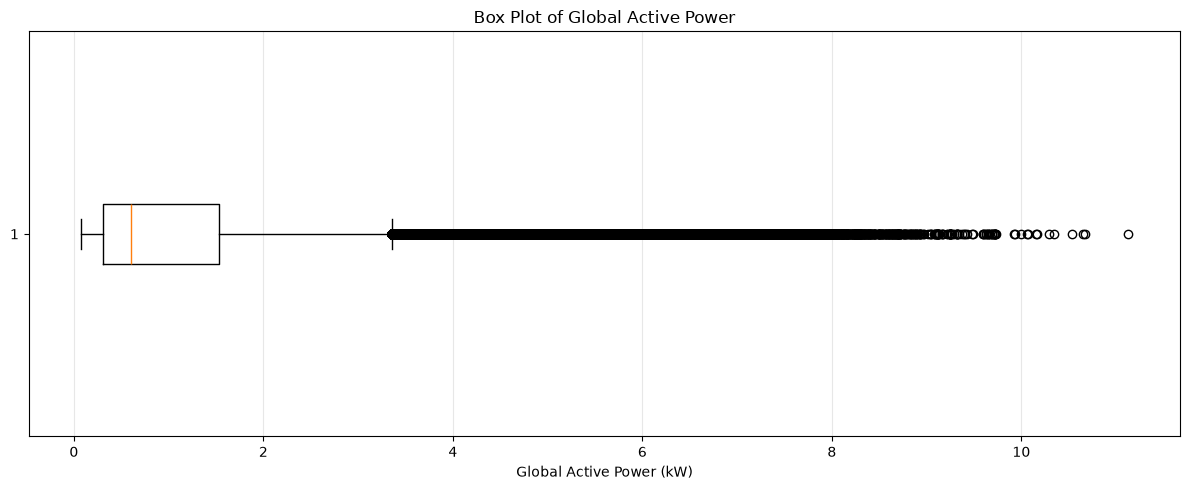

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.boxplot(df['Global_active_power'], vert=False)

plt.title('Box Plot of Global Active Power')
plt.xlabel('Global Active Power (kW)')
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Exploratory Data Analysis Summary

In this project, Exploratory Data Analysis (EDA) was performed on household electricity consumption data to understand its distribution, time-based patterns, and relationships between electrical measurements.

The analysis included:

* Dataset overview and statistical summary.
* Missing-value analysis.
* Distribution and skewness analysis.
* Hourly electricity consumption analysis.
* Daily electricity consumption analysis.
* Weekday versus weekend comparison.
* Monthly electricity consumption analysis.
* Correlation analysis using a heatmap.
* Potential outlier identification using the IQR method.

The findings from these analyses will guide the development of the Electricity Consumption Intelligence Dashboard and help present electricity consumption patterns in an understandable and useful way.

**Important limitation:** The dataset contains missing measurement intervals that were removed during cleaning. Therefore, recorded energy totals may underestimate actual consumption. Statistical relationships and outliers also require careful interpretation.


In [26]:
eda_summary = pd.DataFrame({
    'Analysis': [
        'Dataset',
        'Data Quality',
        'Power Distribution',
        'Peak Consumption Hour',
        'Lowest Average Power Hour',
        'Weekend vs Weekday',
        'Highest Recorded Consumption Day',
        'Highest Recorded Consumption Month',
        'Correlation',
        'Potential High-Power Outliers'
    ],
    'Key Finding': [
        '2,049,280 valid readings',
        'No missing values after cleaning',
        'Right-skewed (skewness = 1.786)',
        '8 PM (1.899 kW average)',
        '4 AM (0.444 kW average)',
        'Weekend: 1.234 kW vs Weekday: 1.035 kW (19.2% higher)',
        '23 December 2006 (79.556 kWh)',
        'December 2007 (1,210.070 kWh)',
        'Active power and intensity: approximately +1.00',
        '94,907 readings (4.63%)'
    ]
})

display(eda_summary)

,Analysis,Key Finding
0,Dataset,"2,049,280 valid readings"
1,Data Quality,No missing values after cleaning
2,Power Distribution,Right-skewed (skewness = 1.786)
3,Peak Consumption Hour,8 PM (1.899 kW average)
4,Lowest Average Power Hour,4 AM (0.444 kW average)
5,Weekend vs Weekday,Weekend: 1.234 kW vs Weekday: 1.035 kW (19.2% ...
6,Highest Recorded Consumption Day,23 December 2006 (79.556 kWh)
7,Highest Recorded Consumption Month,"December 2007 (1,210.070 kWh)"
8,Correlation,Active power and intensity: approximately +1.00
9,Potential High-Power Outliers,"94,907 readings (4.63%)"
